In [2]:
# KDD STEP 1: DOMAIN UNDERSTANDING

PROJECT_NAME = "Anemia Risk Prediction Using Machine Learning"

PROBLEM_STATEMENT = (
    "To develop a machine learning model that predicts anemia risk "
    "based on demographic, nutritional, and health-related factors."
)

RISK_LABELS = {
    0: "Low",
    1: "Medium",
    2: "High"
}

print("Project:", PROJECT_NAME)
print("Problem:", PROBLEM_STATEMENT)
print("Objective: Predict district-level anemia risk using NFHS-5 data.")

Project: Anemia Risk Prediction Using Machine Learning
Problem: To develop a machine learning model that predicts anemia risk based on demographic, nutritional, and health-related factors.
Objective: Predict district-level anemia risk using NFHS-5 data.


In [3]:
# KDD STEP 2: DATA SELECTION

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))

if file_name.lower().endswith(".csv"):
    df = pd.read_csv(file_name)
elif file_name.lower().endswith((".xls", ".xlsx")):
    df = pd.read_excel(file_name)
else:
    raise ValueError("Please upload a CSV, XLS, or XLSX dataset.")

print("Dataset Shape:", df.shape)
display(df.head())
print("Column Names:")
print(df.columns.tolist())

Saving NFHS_5_India_Districts_Factsheet_Data.csv to NFHS_5_India_Districts_Factsheet_Data (1).csv
Dataset Shape: (707, 109)


,District Names,State/UT,Number of Households surveyed,Number of Women age 15-49 years interviewed,Number of Men age 15-54 years interviewed,Female population age 6 years and above who ever attended school (%),Population below age 15 years (%),"Sex ratio of the total population (females per 1,000 males)","Sex ratio at birth for children born in the last five years (females per 1,000 males)",Children under age 5 years whose birth was registered with the civil authority (%),...,Men age 15 years and above wih Mildly elevated blood pressure (Systolic 140-159 mm of Hg and/or Diastolic 90-99 mm of Hg) (%),Men age 15 years and above wih Moderately or severely elevated blood pressure (Systolic ?160 mm of Hg and/or Diastolic ?100 mm of Hg) (%),Men age 15 years and above wih Elevated blood pressure (Systolic ?140 mm of Hg and/or Diastolic ?90 mm of Hg) or taking medicine to control blood pressure (%),Women (age 30-49 years) Ever undergone a screening test for cervical cancer (%),Women (age 30-49 years) Ever undergone a breast examination for breast cancer (%),Women (age 30-49 years) Ever undergone an oral cavity examination for oral cancer (%),Women age 15 years and above who use any kind of tobacco (%),Men age 15 years and above who use any kind of tobacco (%),Women age 15 years and above who consume alcohol (%),Men age 15 years and above who consume alcohol (%)
0,Nicobars,Andaman & Nicobar Islands,882,764,125,78.0,23.0,973,927,98.0,...,32.9,11.1,47.0,13.4,13.2,5.4,63.5,76.8,29.6,64.5
1,North & Middle Andaman,Andaman & Nicobar Islands,874,789,108,82.7,19.8,950,844,100.0,...,22.6,6.0,32.2,1.7,0.3,15.8,46.8,70.5,5.1,45.3
2,South Andaman,Andaman & Nicobar Islands,868,844,134,84.7,21.0,967,935,96.5,...,17.9,6.1,26.9,1.3,0.7,8.0,19.6,50.8,1.7,32.8
3,Srikakulam,Andhra Pradesh,874,780,100,60.0,20.7,1140,1163,95.0,...,14.4,5.5,22.9,1.0,0.2,3.8,7.1,21.3,0.6,28.3
4,Vizianagaram,Andhra Pradesh,902,853,134,56.0,20.6,1114,898,95.4,...,14.8,6.4,25.1,4.9,0.6,7.3,11.4,21.5,0.8,32.3


Column Names:
['District Names', 'State/UT', 'Number of Households surveyed', 'Number of Women age 15-49 years interviewed', 'Number of Men age 15-54 years interviewed', 'Female population age 6 years and above who ever attended school (%)', 'Population below age 15 years (%)', ' Sex ratio of the total population (females per 1,000 males)', 'Sex ratio at birth for children born in the last five years (females per 1,000 males)', 'Children under age 5 years whose birth was registered with the civil authority (%)', 'Deaths in the last 3 years registered with the civil authority (%)', 'Population living in households with electricity (%)', 'Population living in households with an improved drinking-water source1 (%)', 'Population living in households that use an improved sanitation facility2 (%)', 'Households using clean fuel for cooking3 (%)', 'Households using iodized salt (%)', 'Households with any usual member covered under a health insurance/financing scheme (%)', 'Children age 5 years

In [4]:
# KDD STEP 3: DATA INTEGRATION

df.columns = df.columns.astype(str).str.strip()

print("Duplicate Rows:", df.duplicated().sum())

district_candidates = [
    c for c in df.columns
    if "district" in c.lower()
]

state_candidates = [
    c for c in df.columns
    if "state" in c.lower() or "ut" == c.lower()
]

print("Possible District Columns:", district_candidates)
print("Possible State Columns:", state_candidates)

Duplicate Rows: 0
Possible District Columns: ['District Names']
Possible State Columns: ['State/UT']


In [5]:
# KDD STEP 4: DATA CLEANING

def clean_column_names(col):
    col = str(col).strip()
    col = re.sub(r"[^\w\s]", "", col)
    col = re.sub(r"\s+", "_", col)
    return col

df.columns = [clean_column_names(c) for c in df.columns]

df = df.replace(r"^\s*\*\s*$", np.nan, regex=True)
df = df.replace(-99, np.nan)

# Remove duplicate records
df = df.drop_duplicates().reset_index(drop=True)

# Identify district and state columns after cleaning
district_col = next(
    (c for c in df.columns if "district" in c.lower()),
    None
)

state_col = next(
    (c for c in df.columns
     if "state" in c.lower() or c.lower() == "stateut"),
    None
)

# Convert object columns that contain numeric data
for col in df.columns:
    if col not in [district_col, state_col]:
        converted = pd.to_numeric(df[col], errors="coerce")
        if converted.notna().sum() > 0:
            df[col] = converted

numeric_cols = df.select_dtypes(include=np.number).columns

# Replace infinite values and impute missing numeric values
df[numeric_cols] = df[numeric_cols].replace(
    [np.inf, -np.inf], np.nan
)

df[numeric_cols] = df[numeric_cols].fillna(
    df[numeric_cols].median()
)

print("Cleaned Dataset Shape:", df.shape)
print("Remaining Missing Values:", df.isna().sum().sum())

Cleaned Dataset Shape: (707, 109)
Remaining Missing Values: 0


In [6]:
# KDD STEP 5: DATA PREPROCESSING

# Inspect columns that may contain anemia prevalence
anemia_candidates = [
    c for c in df.columns
    if any(word in c.lower() for word in
           ["anaemia", "anemia", "anaemic", "anemic"])
]

print("Possible Anemia Columns:", anemia_candidates)

# Select the actual column after inspecting its name
# Update this value if your dataset uses a different column name.
target_col = next(
    (c for c in anemia_candidates
     if any(word in c.lower()
            for word in ["anaemia", "anemia", "anaemic", "anemic"])),
    None
)

if target_col is None:
    raise ValueError(
        "No anemia-related column found. Inspect the printed column names "
        "and set target_col to the correct anemia prevalence column."
    )

print("Selected Anemia Target:", target_col)
print(df[target_col].describe())

Possible Anemia Columns: ['Children_age_659_months_who_are_anaemic_110_gdl22_', 'Nonpregnant_women_age_1549_years_who_are_anaemic_120_gdl22_', 'Pregnant_women_age_1549_years_who_are_anaemic_110_gdl22_', 'All_women_age_1549_years_who_are_anaemic22_', 'All_women_age_1519_years_who_are_anaemic22_']
Selected Anemia Target: Children_age_659_months_who_are_anaemic_110_gdl22_
count    707.000000
mean      65.858557
std       12.028421
min       24.900000
25%       59.550000
50%       67.700000
75%       74.000000
max       95.500000
Name: Children_age_659_months_who_are_anaemic_110_gdl22_, dtype: float64


In [7]:
# KDD STEP 6: DATA TRANSFORMATION

df[target_col] = pd.to_numeric(df[target_col], errors="coerce")

# Exclude rows with missing target values
df = df.dropna(subset=[target_col]).copy()

q1 = df[target_col].quantile(0.33)
q2 = df[target_col].quantile(0.66)

def assign_risk(value):
    if value < q1:
        return 0
    elif value < q2:
        return 1
    return 2

df["Anaemia_Risk_Level"] = (
    df[target_col].apply(assign_risk)
)

print("Low Risk: Below", round(q1, 2), "%")
print("Medium Risk: From", round(q1, 2), "to", round(q2, 2), "%")
print("High Risk: At or above", round(q2, 2), "%")

print(df["Anaemia_Risk_Level"].value_counts().sort_index())

Low Risk: Below 62.7 %
Medium Risk: From 62.7 to 71.6 %
High Risk: At or above 71.6 %
Anaemia_Risk_Level
0    232
1    234
2    241
Name: count, dtype: int64


In [8]:
# KDD STEP 7: DATA REDUCTION

drop_cols = [
    c for c in [district_col, state_col, target_col,
                "Anaemia_Risk_Level"]
    if c is not None and c in df.columns
]

X = df.drop(columns=drop_cols, errors="ignore")

# Retain numeric predictor columns
X = X.select_dtypes(include=np.number)

# Remove columns with no variation
X = X.loc[:, X.nunique(dropna=False) > 1]

print("Reduced Dataset Shape:", X.shape)
print("Available Numeric Features:", X.columns.tolist())

Reduced Dataset Shape: (707, 106)
Available Numeric Features: ['Number_of_Households_surveyed', 'Number_of_Women_age_1549_years_interviewed', 'Number_of_Men_age_1554_years_interviewed', 'Female_population_age_6_years_and_above_who_ever_attended_school_', 'Population_below_age_15_years_', 'Sex_ratio_of_the_total_population_females_per_1000_males', 'Sex_ratio_at_birth_for_children_born_in_the_last_five_years_females_per_1000_males', 'Children_under_age_5_years_whose_birth_was_registered_with_the_civil_authority_', 'Deaths_in_the_last_3_years_registered_with_the_civil_authority_', 'Population_living_in_households_with_electricity_', 'Population_living_in_households_with_an_improved_drinkingwater_source1_', 'Population_living_in_households_that_use_an_improved_sanitation_facility2_', 'Households_using_clean_fuel_for_cooking3_', 'Households_using_iodized_salt_', 'Households_with_any_usual_member_covered_under_a_health_insurancefinancing_scheme_', 'Children_age_5_years_who_attended_preprimar

Selected Features:
['All_women_age_1519_years_who_are_anaemic22_', 'All_women_age_1549_years_who_are_anaemic22_', 'Nonpregnant_women_age_1549_years_who_are_anaemic_120_gdl22_', 'Women_age_1549_years_whose_Body_Mass_Index_BMI_is_below_normal_BMI_185_kgm221_', 'Number_of_Men_age_1554_years_interviewed', 'Children_under_5_years_who_are_underweight_weightforage18_', 'Sex_ratio_of_the_total_population_females_per_1000_males', 'Women_age_1524_years_who_use_hygienic_methods_of_protection_during_their_menstrual_period5_', 'Female_population_age_6_years_and_above_who_ever_attended_school_', 'Average_outofpocket_expenditure_per_delivery_in_a_public_health_facility_for_last_birth_in_the_5_years_before_the_survey_Rs', 'Men_age_15_years_and_above_wih_Moderately_or_severely_elevated_blood_pressure_Systolic_160_mm_of_Hg_andor_Diastolic_100_mm_of_Hg_', 'Current_Use_of_Family_Planning_Methods_Currently_Married_Women_Age_1549_years_Condom_', 'Number_of_Women_age_1549_years_interviewed', 'Men_age_15_year

/tmp/ipykernel_2243/3253638200.py:45: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


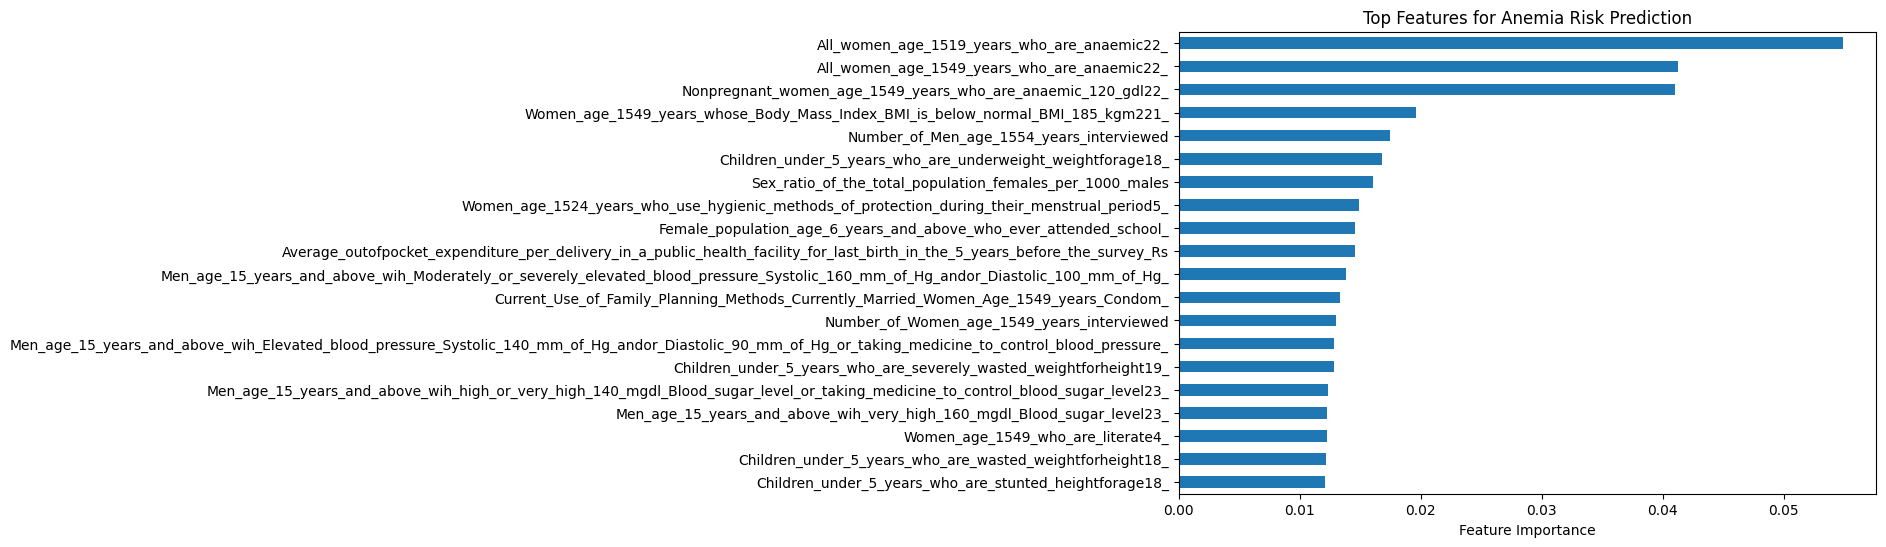

In [9]:
# KDD STEP 8: FEATURE SELECTION

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

y = df["Anaemia_Risk_Level"]

# Align predictors and target
X = X.loc[y.index]

# Split before feature selection
X_train_full, X_test_full, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

selector = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

selector.fit(X_train_full, y_train)

importances = pd.Series(
    selector.feature_importances_,
    index=X_train_full.columns
).sort_values(ascending=False)

top_features = importances.head(
    min(20, len(importances))
).index.tolist()

print("Selected Features:")
print(top_features)

importances.head(20).sort_values().plot(
    kind="barh", figsize=(9, 6)
)
plt.title("Top Features for Anemia Risk Prediction")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

In [10]:
# KDD STEP 9: DATA MINING

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

# Use the selected features consistently
X_train = X_train_full[top_features].copy()
X_test = X_test_full[top_features].copy()

# Fit imputation on training data only
imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=top_features,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=top_features,
    index=X_test.index
)

# Balance class weights using training labels
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

rf = RandomForestClassifier(
    n_estimators=400,
    max_depth=12,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.03,
    max_depth=5,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

# Train individual models
rf.fit(X_train, y_train)

xgb.fit(
    X_train,
    y_train,
    sample_weight=sample_weights
)

# Combine model predictions using a Logistic Regression meta-model
stack_model = StackingClassifier(
    estimators=[
        ("rf", RandomForestClassifier(
            n_estimators=300,
            max_depth=12,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )),
        ("xgb", XGBClassifier(
            n_estimators=300,
            learning_rate=0.03,
            max_depth=5,
            subsample=0.9,
            colsample_bytree=0.9,
            objective="multi:softprob",
            eval_metric="mlogloss",
            random_state=42,
            n_jobs=-1
        ))
    ],
    final_estimator=LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),
    cv=5,
    n_jobs=-1
)

stack_model.fit(X_train, y_train)

print("All three models trained successfully.")

All three models trained successfully.



Random Forest
Accuracy: 0.6408
              precision    recall  f1-score   support

         Low       0.76      0.74      0.75        47
      Medium       0.47      0.53      0.50        47
        High       0.72      0.65      0.68        48

    accuracy                           0.64       142
   macro avg       0.65      0.64      0.64       142
weighted avg       0.65      0.64      0.64       142



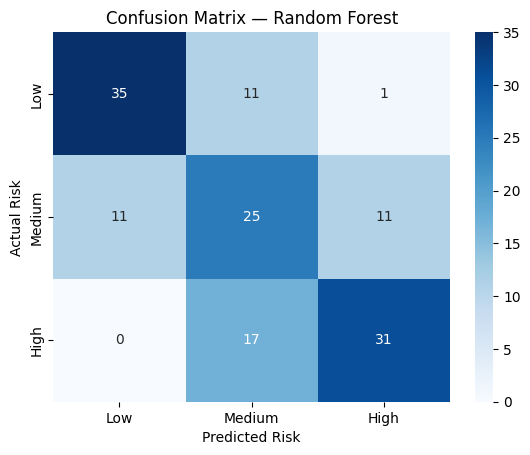


XGBoost
Accuracy: 0.6268
              precision    recall  f1-score   support

         Low       0.77      0.70      0.73        47
      Medium       0.46      0.55      0.50        47
        High       0.70      0.62      0.66        48

    accuracy                           0.63       142
   macro avg       0.64      0.63      0.63       142
weighted avg       0.64      0.63      0.63       142



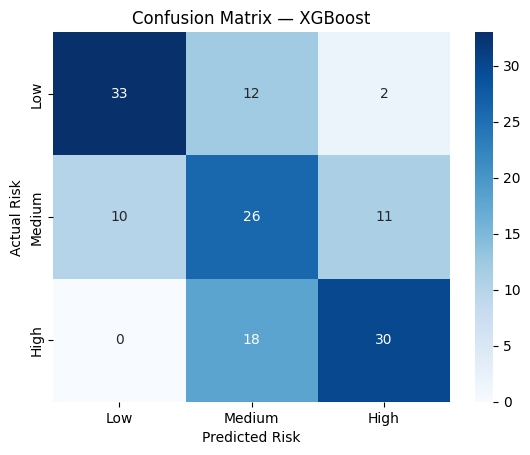


Stacking Ensemble
Accuracy: 0.662
              precision    recall  f1-score   support

         Low       0.78      0.77      0.77        47
      Medium       0.50      0.55      0.53        47
        High       0.73      0.67      0.70        48

    accuracy                           0.66       142
   macro avg       0.67      0.66      0.67       142
weighted avg       0.67      0.66      0.67       142



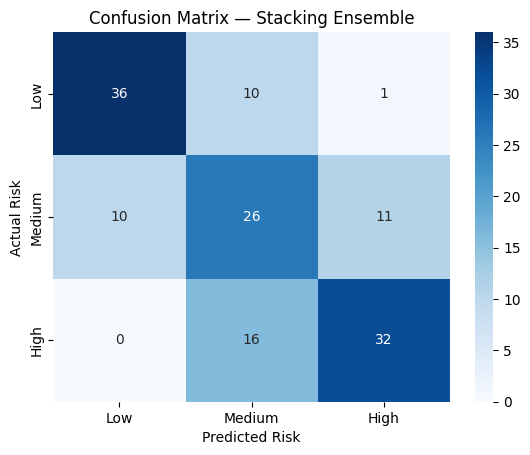

,Model,Accuracy
2,Stacking Ensemble,0.661972
0,Random Forest,0.640845
1,XGBoost,0.626761


In [11]:
# KDD STEP 10: PATTERN EVALUATION

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

models = {
    "Random Forest": rf,
    "XGBoost": xgb,
    "Stacking Ensemble": stack_model
}

results = []

for name, model in models.items():
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions)
    })

    print(f"\n{'=' * 45}")
    print(name)
    print("Accuracy:", round(
        accuracy_score(y_test, predictions), 4
    ))
    print(classification_report(
        y_test,
        predictions,
        labels=[0, 1, 2],
        target_names=["Low", "Medium", "High"],
        zero_division=0
    ))

    cm = confusion_matrix(
        y_test, predictions, labels=[0, 1, 2]
    )

    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["Low", "Medium", "High"],
        yticklabels=["Low", "Medium", "High"]
    )
    plt.title(f"Confusion Matrix — {name}")
    plt.xlabel("Predicted Risk")
    plt.ylabel("Actual Risk")
    plt.show()

results_df = pd.DataFrame(results).sort_values(
    "Accuracy", ascending=False
)

display(results_df)

In [12]:
# KDD STEP 11: MODEL VALIDATION

from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    stack_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=1
)

print("Cross-Validation Scores:", np.round(cv_scores, 4))
print("Mean CV Accuracy:", round(cv_scores.mean(), 4))
print("Standard Deviation:", round(cv_scores.std(), 4))

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("Selected Features:", len(top_features))

Cross-Validation Scores: [0.6195 0.7257 0.6195 0.708  0.5664]
Mean CV Accuracy: 0.6478
Standard Deviation: 0.0599

Training Samples: 565
Testing Samples: 142
Selected Features: 20


In [15]:
# KDD STEP 12: KNOWLEDGE PRESENTATION AND DEPLOYMENT

def predict_location():
    district = input("Enter District Name: ").strip().lower()

    if district_col is None:
        print("❌ District column not found in dataset.")
        return

    district_names = (
        df[district_col].astype(str).str.strip().str.lower()
    )

    row = df.loc[district_names == district]

    if row.empty:
        print("❌ District not found")
        print("👉 Try:", df[district_col].head(10).tolist())
        return

    # Prepare exactly the same features used for training
    X_input = row[top_features].copy()

    X_input = pd.DataFrame(
        imputer.transform(X_input),
        columns=top_features,
        index=X_input.index
    )

    pred_class = int(stack_model.predict(X_input)[0])
    risk = RISK_LABELS[pred_class]

    # This is the observed dataset percentage, not a separately
    # predicted continuous anemia percentage.
    anemia_value = float(row[target_col].iloc[0])

    print("\n📊 Output Example\n")
    print(f"📍 District: {row[district_col].iloc[0]}")
    print(f"🩸 Anemia % (NFHS-5): {anemia_value:.2f}")
    print(f"⚠ Risk Level: {risk}\n")

    print("💡 Suggestions to Reduce Anaemia:\n")

    if risk == "High":
        print("- Promote iron-rich foods and balanced nutrition")
        print("- Encourage appropriate screening and health checkups")
        print("- Improve access to maternal healthcare")
        print("- Strengthen nutrition and public-health programs")

    elif risk == "Medium":
        print("- Improve dietary diversity and nutrition awareness")
        print("- Encourage regular health checkups")
        print("- Strengthen community awareness programs")

    else:
        print("- Maintain balanced nutrition and healthy habits")
        print("- Continue routine public-health monitoring")

    print("\n⚠ This is a district-level screening indicator,")
    print("not an individual diagnosis or medical recommendation.")


predict_location()

Enter District Name: Nagpur

📊 Output Example

📍 District: Nagpur 
🩸 Anemia % (NFHS-5): 70.50
⚠ Risk Level: Medium

💡 Suggestions to Reduce Anaemia:

- Improve dietary diversity and nutrition awareness
- Encourage regular health checkups
- Strengthen community awareness programs

⚠ This is a district-level screening indicator,
not an individual diagnosis or medical recommendation.


In [14]:
# FINAL PROJECT SUMMARY

print("\n--- 📊 Dataset Split Summary ---")
print("Total District Records:", len(df))
print("Total Numeric Features Before Selection:", X.shape[1])
print("Total Features Used:", len(top_features))
print("Districts Used for Training:", len(X_train))
print("Districts Used for Testing:", len(X_test))

print("\n--- Class Distribution ---")
print("Training Set:\n", y_train.value_counts().sort_index())
print("Testing Set:\n", y_test.value_counts().sort_index())

print("\n--- 🏁 Conclusion ---")
print(
    "The model uses NFHS-5 district-level indicators to classify "
    "anemia prevalence into Low, Medium, and High risk categories. "
    "Its performance is assessed using a held-out test set, "
    "classification metrics, confusion matrices, and cross-validation."
)


--- 📊 Dataset Split Summary ---
Total District Records: 707
Total Numeric Features Before Selection: 106
Total Features Used: 20
Districts Used for Training: 565
Districts Used for Testing: 142

--- Class Distribution ---
Training Set:
 Anaemia_Risk_Level
0    185
1    187
2    193
Name: count, dtype: int64
Testing Set:
 Anaemia_Risk_Level
0    47
1    47
2    48
Name: count, dtype: int64

--- 🏁 Conclusion ---
The model uses NFHS-5 district-level indicators to classify anemia prevalence into Low, Medium, and High risk categories. Its performance is assessed using a held-out test set, classification metrics, confusion matrices, and cross-validation.
